Дополнительное задание
1. Ознакомиться с алгоритмами динамической кластеризации t-SNE и UMAP
2. Выберете набор данных и сравните работу статических и динамических моделей

t-SNE - t-Distributed Stohastic Neighbor Embedding (Распеределенное стохастическое соседнее встраивание)

Является нелинейным алгоритмом снижения размерности данных. Является стохастической (вероятностной), требует множество вычислительных ресурсов.

In [2]:
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import numpy as np


np.random.seed(42)

X = np.zeros((150, 6))
prev_i = 0

for i in range(30, X.shape[0]+1, 30):
    for j in range(0, X.shape[1], 2):
        X[prev_i:i, j] = np.random.normal(loc=np.random.randint(-1, 1), scale=.3, size=30)
        X[prev_i:i, j+1] = np.random.normal(loc=np.random.randint(-1, 1), scale=.5, size=30)
    prev_i = i

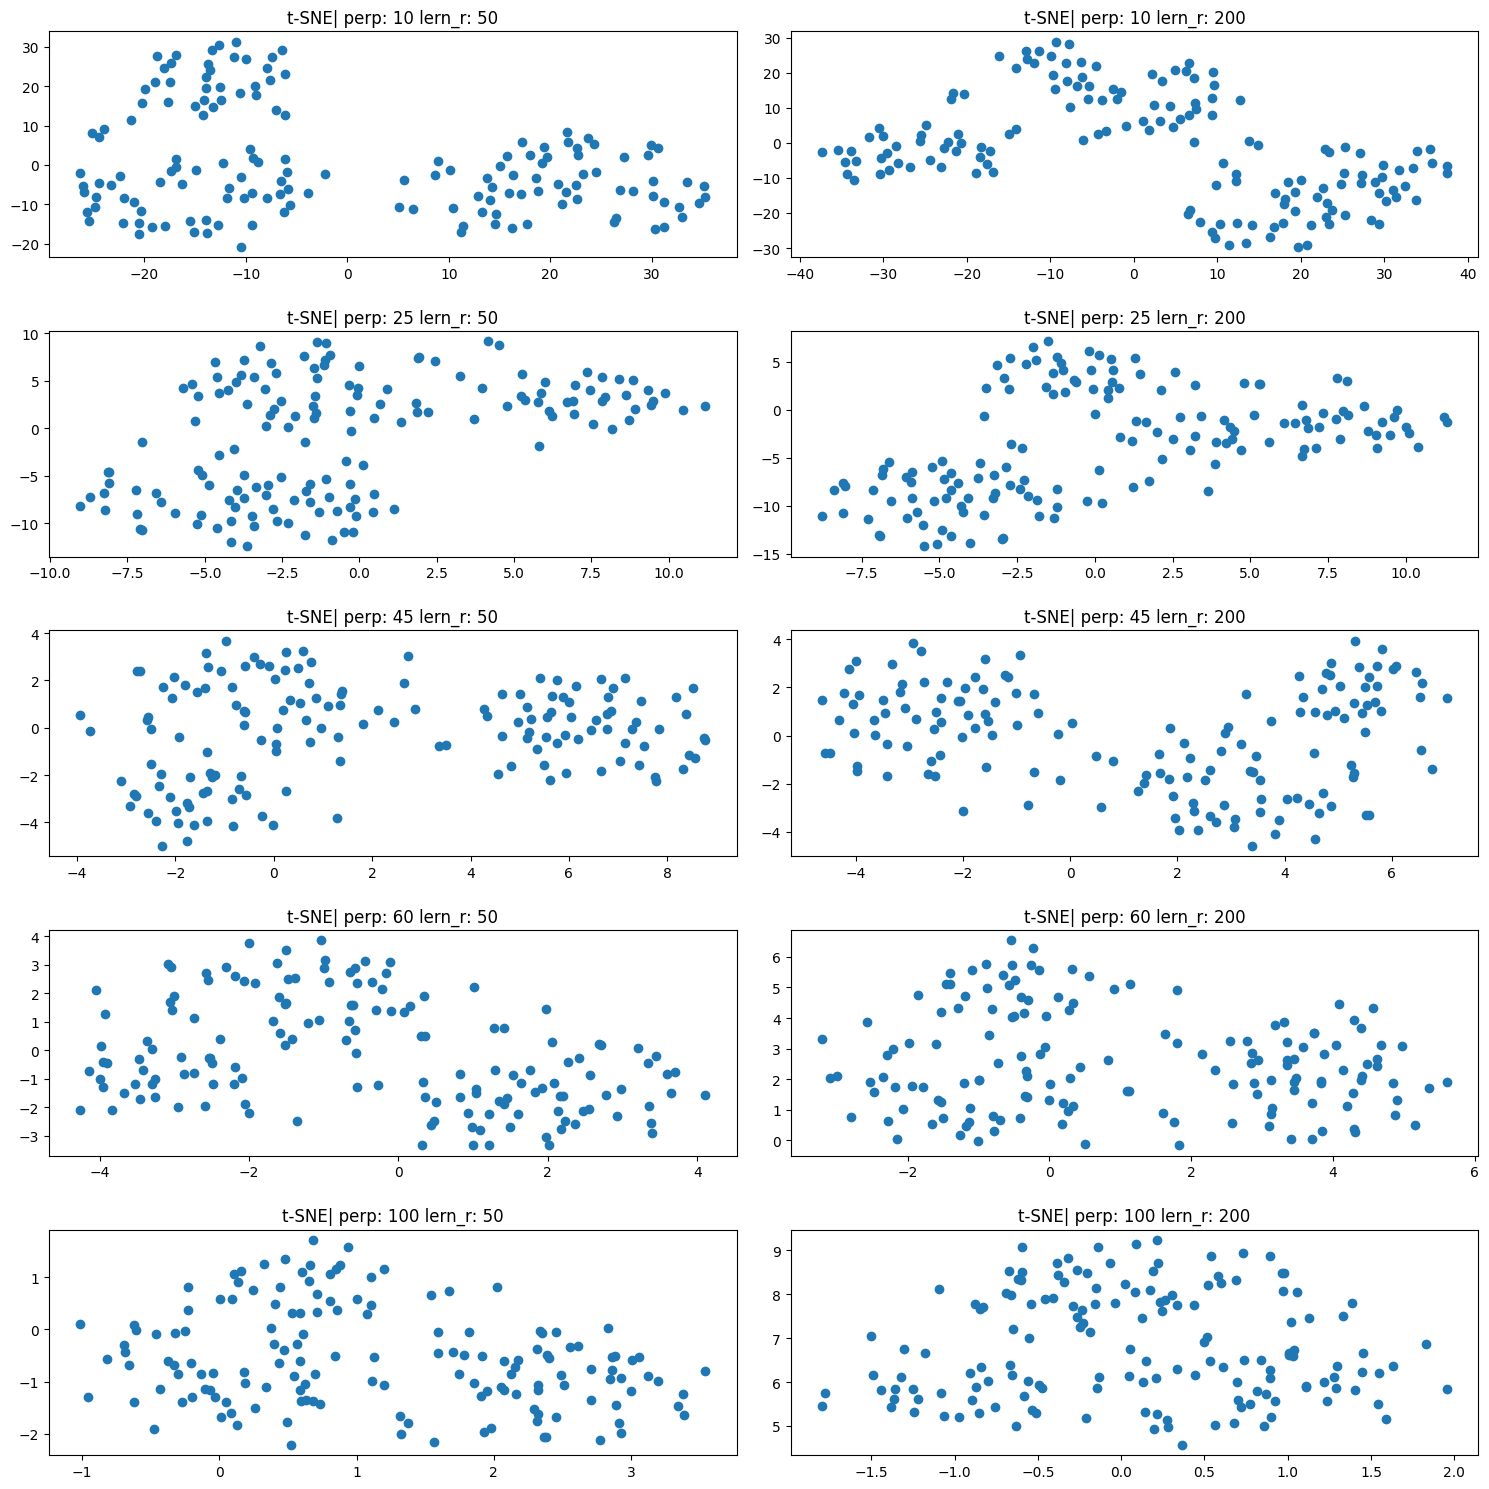

In [3]:
import itertools


fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(15, 15))

tsne_flat = axes.flatten()

perplexities = [10, 25, 45, 60, 100]
learning_rates = [50, 200]

grid = list(itertools.product(perplexities, learning_rates))

for i, ax in enumerate(tsne_flat):
    perp, lear_rate = grid[i]
    tsne = TSNE(n_components=2, perplexity=perp, learning_rate=lear_rate)
    X_embedded = tsne.fit_transform(X)
    ax.scatter(X_embedded[:, 0], X_embedded[:, 1])
    ax.set_title('t-SNE| perp: {:} lern_r: {:}'.format(perp, lear_rate))

plt.tight_layout(h_pad=2)
plt.show()

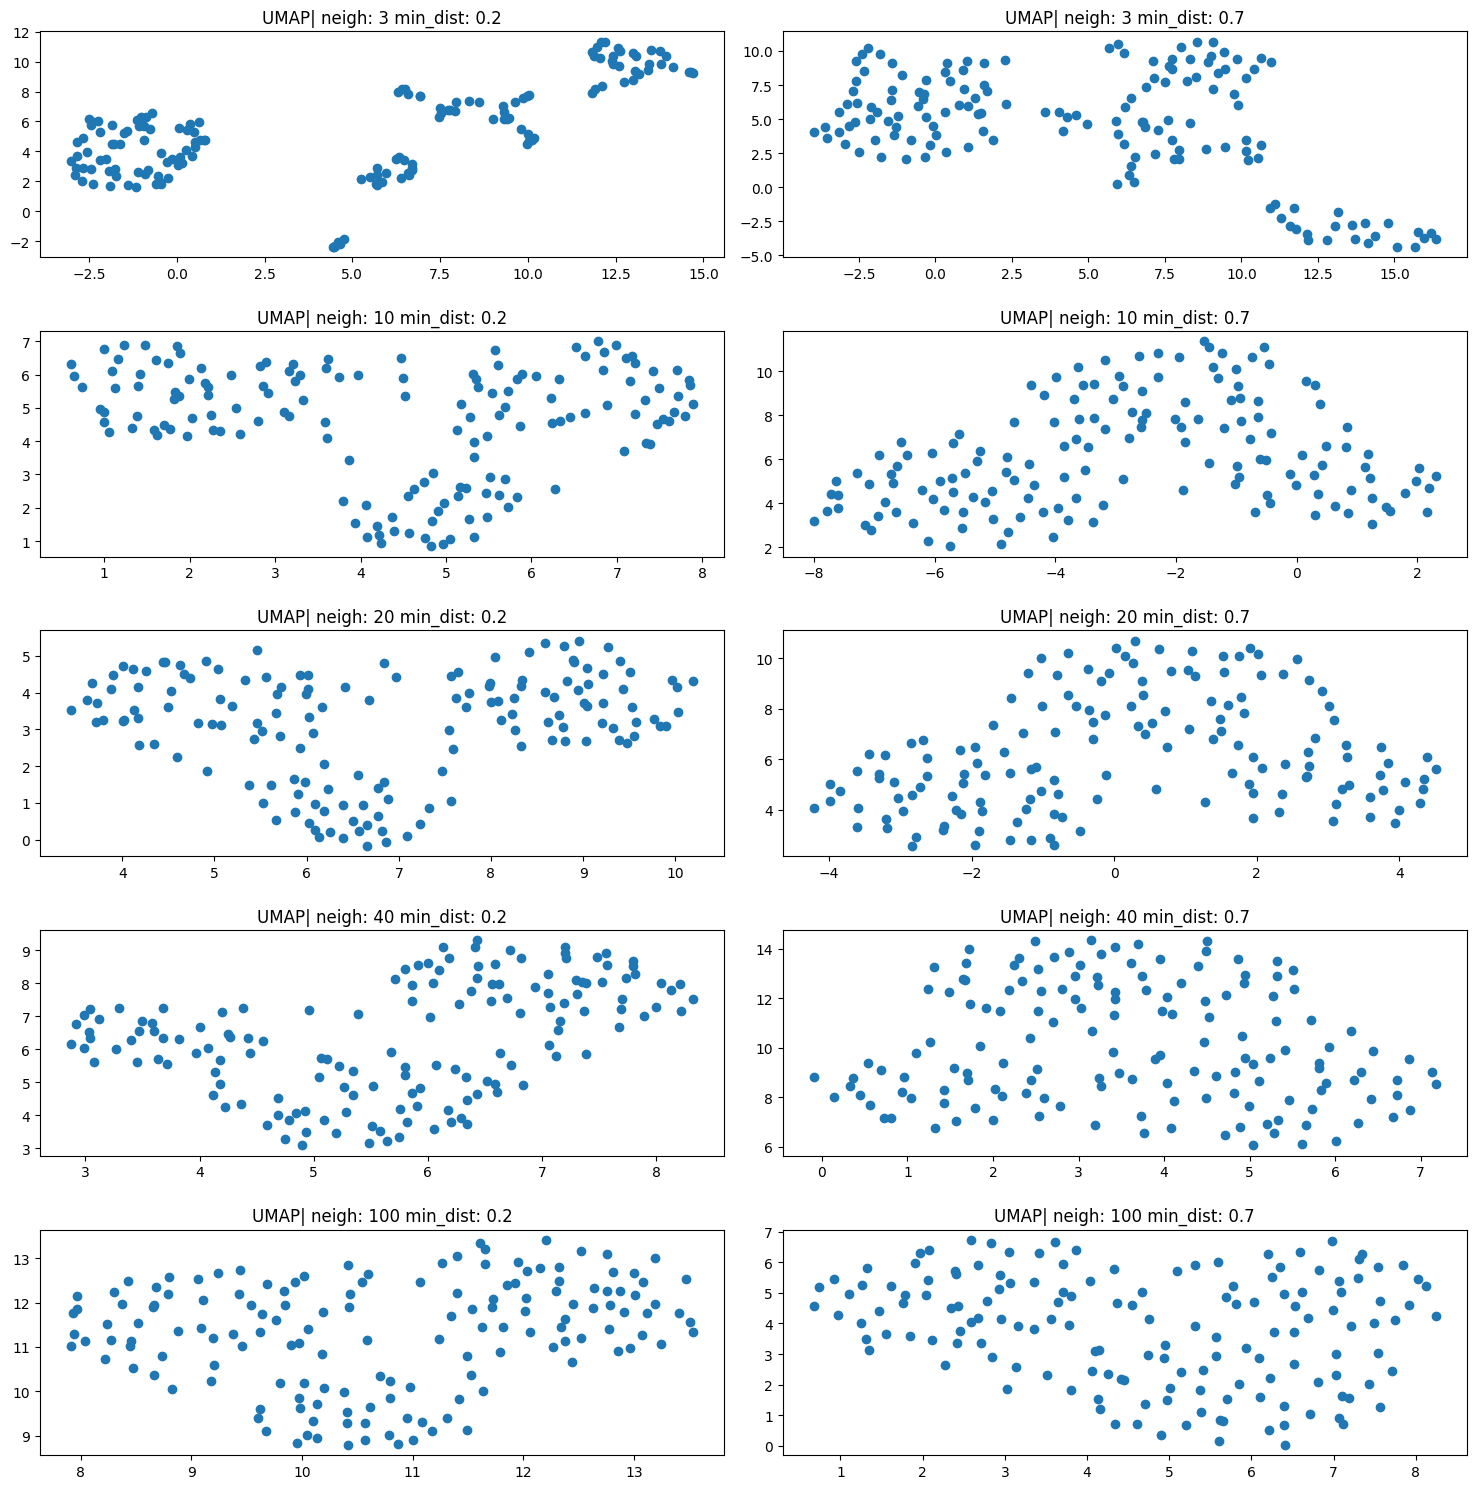

In [4]:
import umap
import itertools


fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(15, 15))

umap_flat = axes.flatten()

neighbors = [3, 10, 20, 40, 100]
min_dist = [0.2, 0.7]

grid = list(itertools.product(neighbors, min_dist))

for i, ax in enumerate(umap_flat):
    neig, dist = grid[i]
    X_embedded = umap.UMAP(n_neighbors=neig, n_components=2, min_dist=dist).fit_transform(X)
    ax.scatter(X_embedded[:, 0], X_embedded[:, 1])
    ax.set_title('UMAP| neigh: {:} min_dist: {:}'.format(neig, dist))

plt.tight_layout(h_pad=2)
plt.show()

In [5]:
# from scanpy.datasets import pbmc3k_processed
# 
# data = pbmc3k_processed()

In [6]:
import scanpy as sc


data = sc.read_h5ad('D:\\MIREA\\DPO\\Learning\\Practic1_8\\data\\pbmc3k_processed.h5ad')

X = data.X
y = data.obs['louvain']

d:\MIREA\DPO\.venv3_11_8\Lib\site-packages\anndata\_io\h5ad.py:267: FutureWarning: Moving element from .uns['neighbors']['distances'] to .obsp['distances'].

This is where adjacency matrices should go now.
  return AnnData(**{
d:\MIREA\DPO\.venv3_11_8\Lib\site-packages\anndata\_io\h5ad.py:267: FutureWarning: Moving element from .uns['neighbors']['connectivities'] to .obsp['connectivities'].

This is where adjacency matrices should go now.
  return AnnData(**{


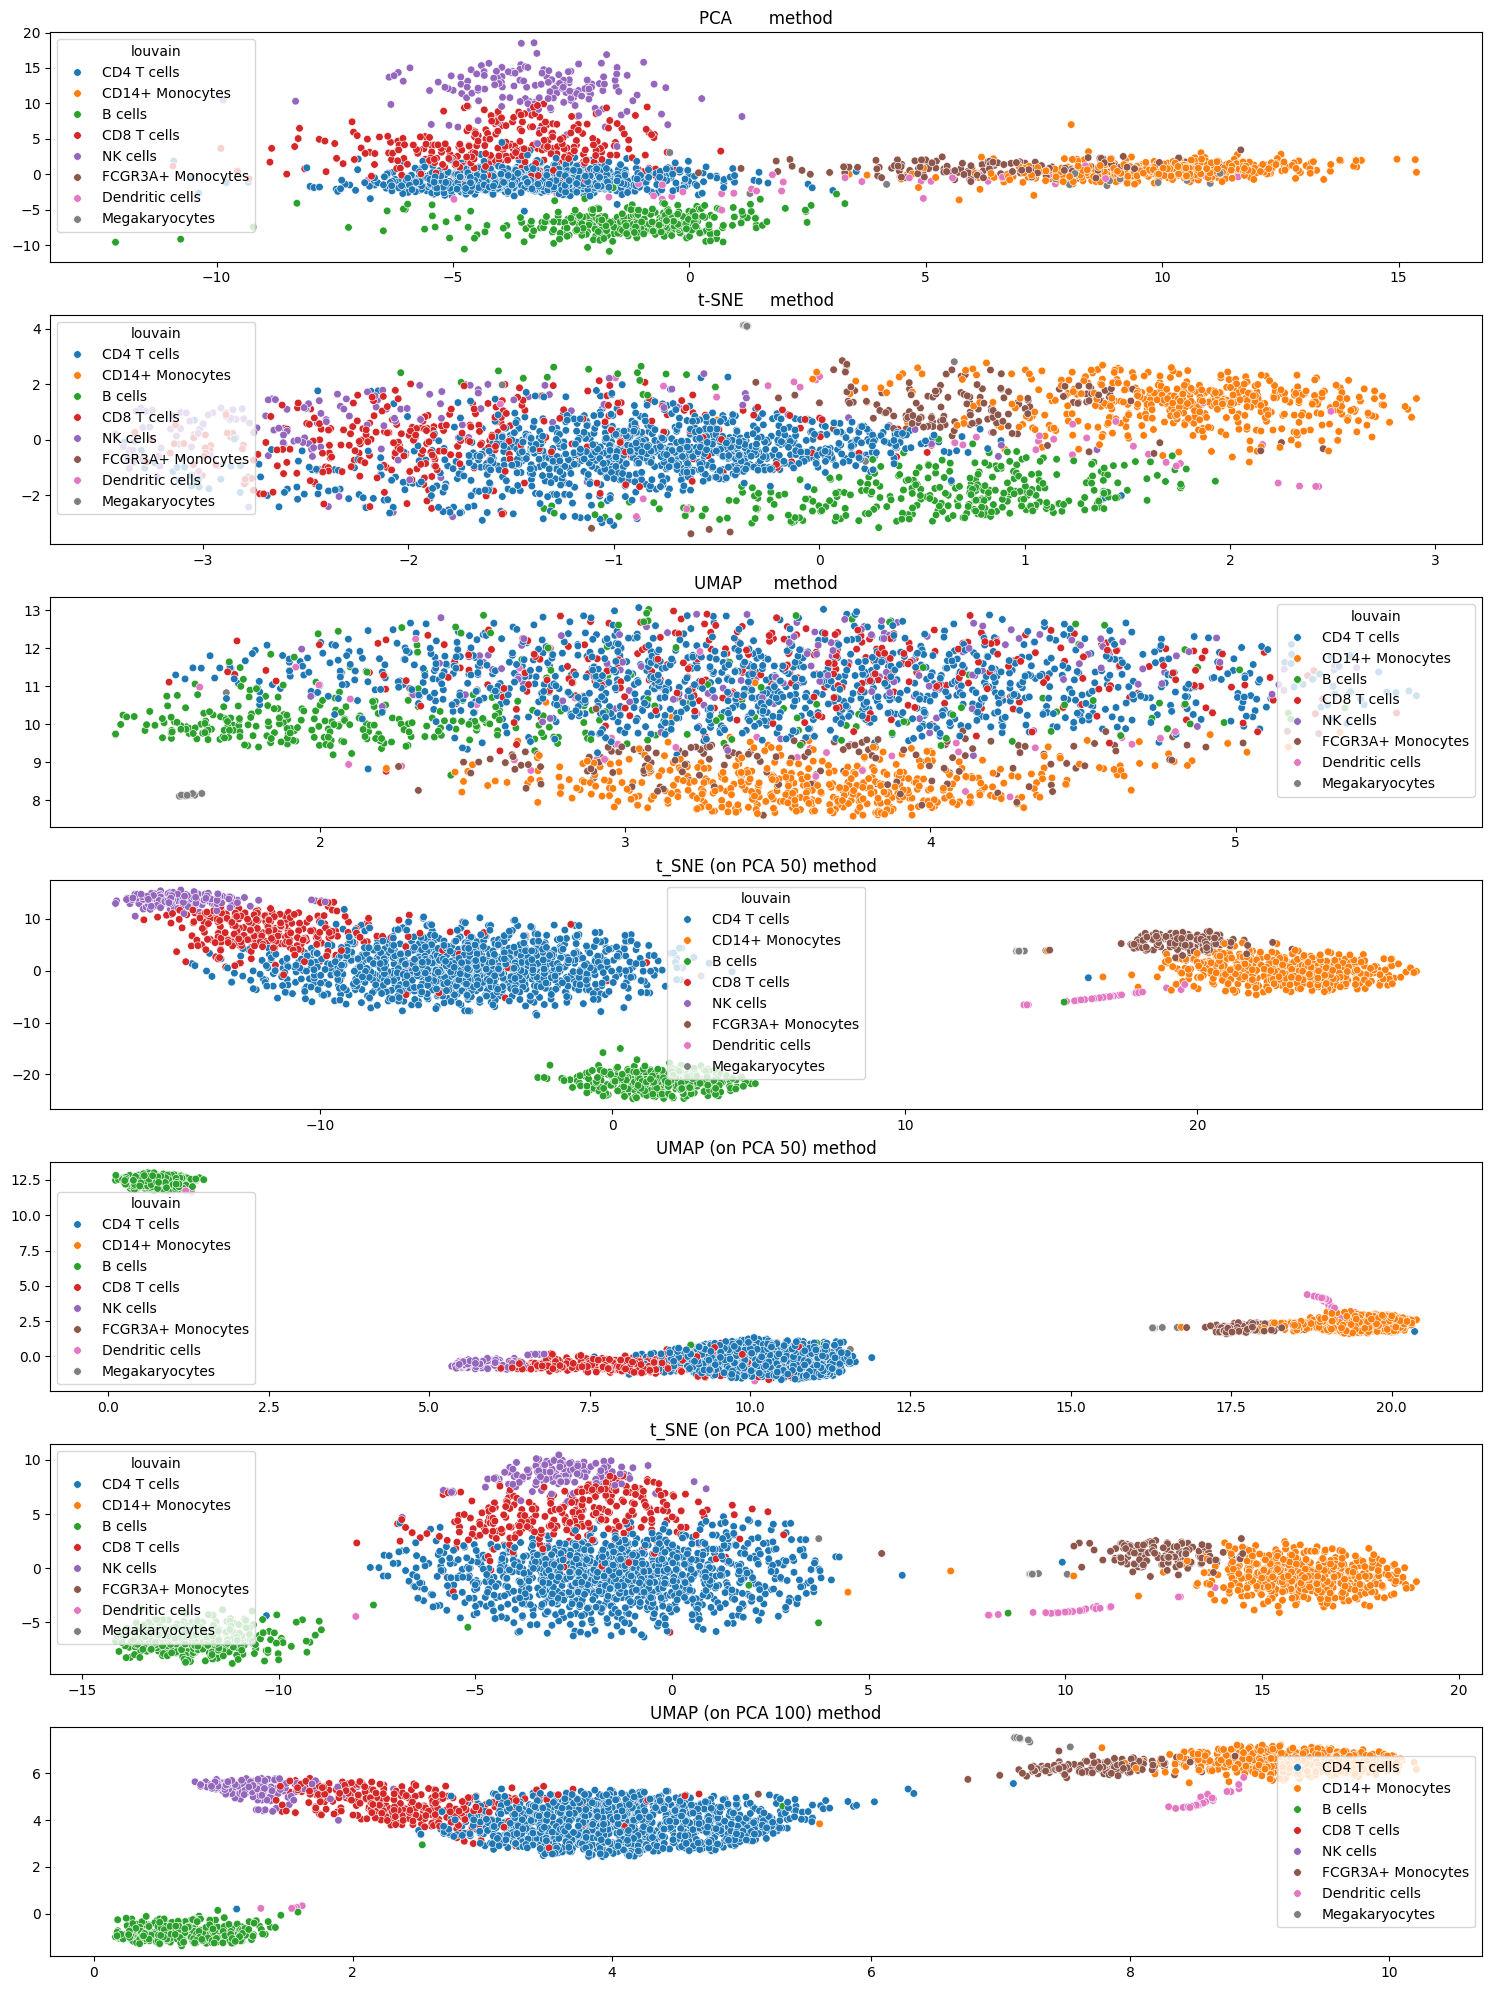

In [25]:
from sklearn.decomposition import PCA
import seaborn as sns


fig, axes = plt.subplots(nrows=7, ncols=1, figsize=(15, 20))

ax_flat = axes.flatten()

models = {'PCA': PCA(n_components=2),
          't-SNE': TSNE(n_components=2, perplexity=50),
          'UMAP': umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1),
          't_SNE (on PCA 50)': TSNE(n_components=2, perplexity=50),
          'UMAP (on PCA 50)': umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1),
          't_SNE (on PCA 100)': TSNE(n_components=2, perplexity=50),
          'UMAP (on PCA 100)': umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1)}

PCA_data_50 = PCA(n_components=50).fit_transform(X)
PCA_data_100 = PCA(n_components=100).fit_transform(X)
for ax, (name, method) in zip(ax_flat, models.items()):
    if name[-3:] == '50)':
        X_embedded = method.fit_transform(PCA_data_50)
    elif name[-3:] == '00)':
        X_embedded = method.fit_transform(PCA_data_100)
    else:
        X_embedded = method.fit_transform(X)
    sns.scatterplot(x=X_embedded[:, 0], y=X_embedded[:, 1], hue=y, ax=ax, s=30, palette='tab10', legend='brief')
    ax.set_title('%-9s method' % name)

plt.legend(loc='right')
plt.tight_layout(h_pad=0.5)
plt.show()